# Correcting pupil foreshortening

<div class="alert alert-warning">

**Experimental:** The method works on simulated data, but it has not been
validated on real recordings yet, and the API will change. A fitted
model cannot yet be applied to the data with a single method call; the
correction is applied by hand below.

</div>

Video-based eye trackers measure the pupil as it appears to the camera.
When the eye looks away from the camera, the pupil is seen at an angle
and appears smaller, even though its true size does not change. This
*pupil foreshortening error* can be large compared to the effects of
interest, and it is a problem whenever gaze position differs between
conditions.

If $\alpha$ is the angle between the direction from the eye to the
camera and the direction of gaze, the measured pupil size $A$ is related
to the true size $A_0$ by

$$A(t) = A_0(t) \cdot \cos\alpha(x(t), y(t)),$$

where $x, y$ is the gaze position on the screen. $\alpha$ depends on the
geometry of the setup: the distance between eye and screen, and the
position of the camera. The details of the model and the fitting
procedure are described in [the algorithm description](foreshortening_correction_algorithm.md).

In [1]:
# hide warnings that are not relevant here
import warnings
warnings.filterwarnings("ignore", message="Unknown solver options")
warnings.filterwarnings("ignore", message="parameter: plain number")

In [2]:
import pypillometry as pp
from pypillometry import u
import numpy as np
import matplotlib.pyplot as plt

pp.logging_set_level("WARNING")

## The experimental setup

The geometry is described by an `ExperimentalSetup`: screen resolution
and physical size, the distance from the eye to the screen, and the
position of the camera relative to the eye, in spherical coordinates
($\theta$: angle from the line of sight to the screen center,
$\phi$: direction around it, $r$: distance). Here, the camera sits below
the screen ($\phi = -90°$), 20° below the line of sight:

In [3]:
setup = pp.ExperimentalSetup(
    screen_resolution=(1920, 1080),
    physical_screen_size=("52 cm", "29 cm"),
    eye_to_screen_center="60 cm",
    camera_spherical=("20 deg", "-90 deg", "70 cm"),
)
setup

ExperimentalSetup(
  screen=1920x1080px
  physical=520x290mm
  d=600mm
  camera: r=700mm, θ=20.0°, φ=-90.0°
)

For your own data, set these values with `d.set_experimental_setup()`.
Eye-to-screen distance and screen size are easy to measure; the camera
angles are harder, which is why the method below estimates them from
the data.

## Simulated data

`generate_foreshortening_data()` simulates two minutes of recording: a
slowly changing true pupil size $A_0$, fixations at random places on the
screen, the resulting foreshortening and some measurement noise. The true
values are kept in `sim_data`:

FakeFakeEyeData(supuleku, 3.2MiB):
 n                 : 60000
 sampling_rate     : 500
 eyes              : ['left']
 data              : ['left_x', 'left_y', 'left_pupil']
 nevents           : 0
 experimental_setup: {'screen_resolution': (1920, 1080), 'physical_screen_size_mm': (520.0, 290.0), 'eye_to_screen_distance_mm': np.float64(600.0), 'camera_distance_mm': np.float64(700.0), 'camera_angles_deg': (np.float64(19.999999999999993), np.float64(-90.0))}
 calibration       : not available
 duration_minutes  : 2.0
 start_min         : 0.0
 end_min           : 1.9999666666666667
 params            : {}
 nblinks           : {}
 blinks            : {'left': None}
 glimpse           : EyeDataDict(vars=3,n=60000,shape=(60000,)): 
  left_x (float64): 179.3079109382324, 179.3079109382324, 179.3079109382324, 179.3079109382324, 179.3079109382324...
  left_y (float64): 830.902834943248, 830.902834943248, 830.902834943248, 830.902834943248, 830.902834943248...
  left_pupil (float64): 671.0408184163064, 681.3718232549013, 681.0167318094741, 666.7572984335031, 667.4368546882736...

 History:
 *, sim_fct=generate_foreshortening_data, sim_data=['left_A0', 'left_cosalpha'])
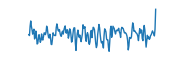
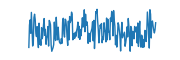
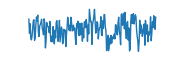

In [4]:
fd = pp.generate_foreshortening_data(experimental_setup=setup, duration=120,
                                     fs=500, seed=42)
true_pupil = np.asarray(fd.sim_data["left_A0"])
fd

The measured pupil size depends on where the eye looks. Points far away
from the camera (at the top of the screen) give the smallest values:

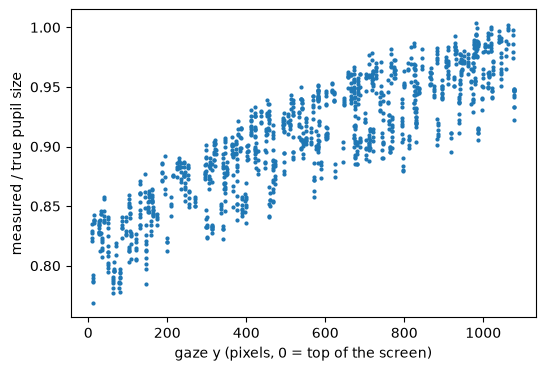

In [5]:
measured = np.asarray(fd["left_pupil"])
y_px = np.asarray(fd["left_y"])

plt.figure(figsize=(6, 4))
plt.scatter(y_px[::50], (measured / true_pupil)[::50], s=4)
plt.xlabel("gaze y (pixels, 0 = top of the screen)")
plt.ylabel("measured / true pupil size");

## A simple correction

`correct_pupil_foreshortening()` uses a simple geometric correction that
only needs the eye-to-screen distance. It assumes that the pupil appears
undistorted when the eye looks at the screen center, i.e. that the
camera is right behind the screen center:

In [6]:
simple = fd.correct_pupil_foreshortening(inplace=False)
simple_pupil = np.asarray(simple["left_pupil"])

## Fitting the camera position

`fit_foreshortening()` estimates the camera angles $\theta$ and $\phi$
together with the time course of the true pupil size, which is modeled
as a smooth B-spline. The idea is that the same true pupil size seen
from different angles has to produce the measured values. The data are
low-pass filtered and downsampled before fitting.

In [7]:
cal = fd.fit_foreshortening("left", verbose=False)
cal

ForeshorteningCalibration(eye='left', theta=16.4°, phi=-89.5°, n_coeffs=124, R²=0.948, RMSE=21.995)

The estimated angles are close to the true values ($\theta = 20°$,
$\phi = -90°$):

In [8]:
print(f"theta = {np.degrees(cal.theta):.1f} deg, phi = {np.degrees(cal.phi):.1f} deg")

theta = 16.4 deg, phi = -89.5 deg


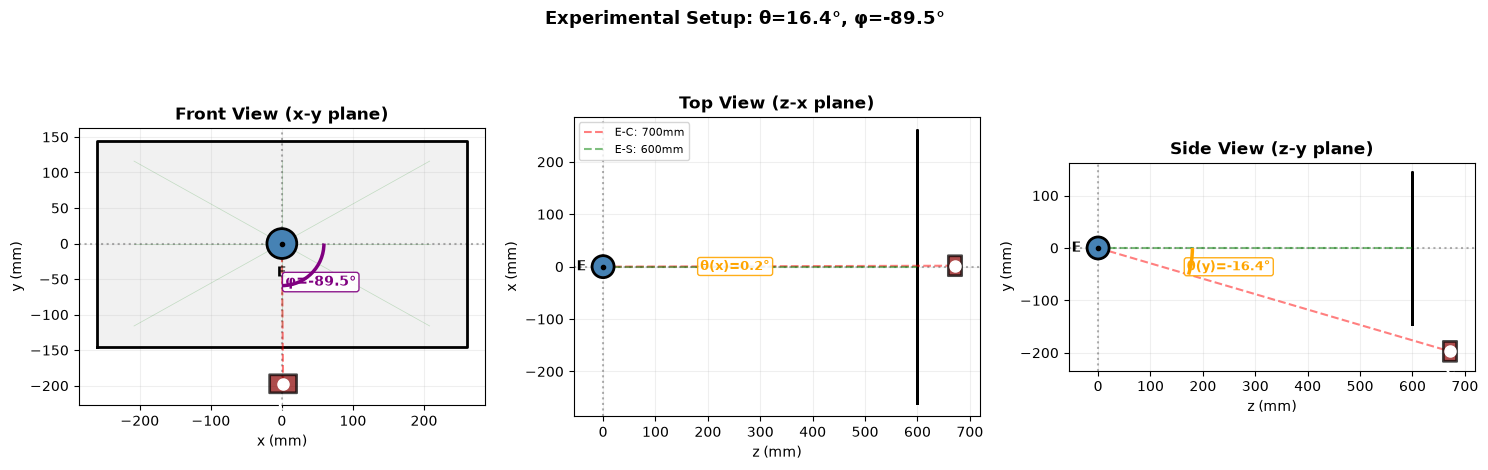

In [9]:
fd.plot.plot_experimental_setup(calibration=cal);

The fitted model gives a correction factor $1/\cos\alpha$ for every gaze
position. Multiplying the measured pupil size by it gives the corrected
signal:

In [10]:
factor = cal.get_correction_factor(fd["left_x"], fd["left_y"])
fitted_pupil = np.asarray(fd["left_pupil"] * factor)

## Comparison

Since the data are simulated, we can compare each version with the true
pupil size:

In [11]:
def rmse(x):
    return np.sqrt(np.nanmean((x - true_pupil) ** 2))

for name, signal in [("measured", measured), ("simple correction", simple_pupil),
                     ("fitted model", fitted_pupil)]:
    print(f"{name:18s} RMSE = {rmse(signal):5.1f}")

measured           RMSE =  79.7
simple correction  RMSE =  55.9
fitted model       RMSE =  17.8


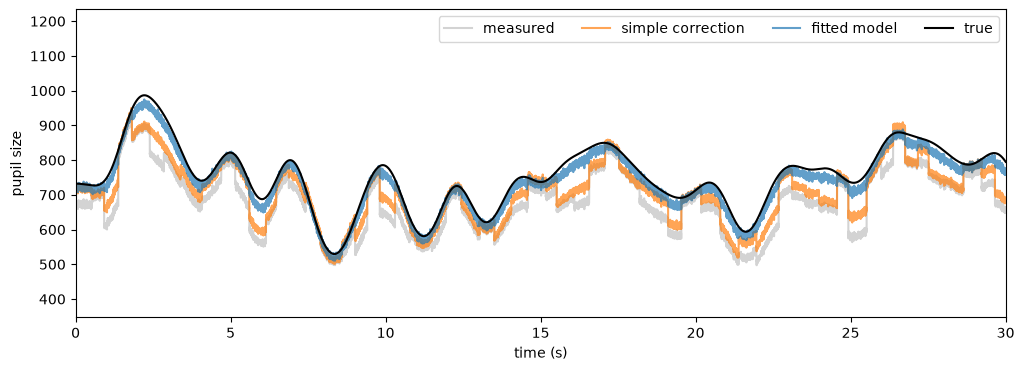

In [12]:
t = fd.tx / 1000
plt.figure(figsize=(12, 4))
plt.plot(t, measured, color="lightgrey", label="measured")
plt.plot(t, simple_pupil, color="tab:orange", alpha=0.7, label="simple correction")
plt.plot(t, fitted_pupil, color="tab:blue", alpha=0.7, label="fitted model")
plt.plot(t, true_pupil, color="black", label="true")
plt.xlim(0, 30)
plt.xlabel("time (s)")
plt.ylabel("pupil size")
plt.legend(ncol=4);

The simple correction helps only partly, because the camera is not
behind the screen center. The fitted model removes most of the error.

## Open issues

- The fitted correction is not yet available as a method of the data
  objects (it has to be applied by hand as above).
- Only one eye is fitted at a time, and screen offset and tilt in the
  experimental setup are not taken into account.
- The method still needs to be validated on real data, e.g., with a
  calibration task in which participants fixate points across the
  screen.